# Optimized Plant Disease Classification with EfficientNetB0
This notebook implements an optimized plant disease classification model using EfficientNetB0. The goal is to achieve faster training and a smaller model size (under 100MB) while maintaining high accuracy. Key optimizations include using a lightweight base model, reduced image size, and efficient data loading practices.

## 1. Imports and Setup

In [1]:
import os
import re
import json
import numpy as np
import pandas as pd
from glob import glob

import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import mixed_precision
from tensorflow.keras.applications import EfficientNetB0 # Changed from MobileNetV2

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import albumentations as A # For advanced augmentation, though Keras layers are used initially

# --- GPU and Performance Setup ---
print(f"TensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        # Set memory growth to avoid allocating all GPU memory at once
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"GPUs Available: {len(gpus)}")
        strategy = tf.distribute.MirroredStrategy()
        print(f"Number of devices for distributed training: {strategy.num_replicas_in_sync}")
    except RuntimeError as e:
        print(e)
else:
    print("No GPU devices found. Training will run on CPU.")
    strategy = tf.distribute.OneDeviceStrategy(device="/cpu:0")

# Enable mixed precision training for faster computation and reduced memory usage
mixed_precision.set_global_policy("float32")
print("Mixed precision clossed.")

2026-05-11 22:40:49.639889: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778539249.896257      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778539249.968071      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1778539250.572136      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778539250.572213      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1778539250.572217      23 computation_placer.cc:177] computation placer alr

TensorFlow Version: 2.19.0
GPUs Available: 2
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Number of devices for distributed training: 2
Mixed precision clossed.


I0000 00:00:1778539287.706424      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1778539287.713885      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


## 2. Unified Label Ontology (FINAL CLEAN LABEL SPACE)

In [2]:
UNIFIED_CLASSES = [
    # Apple
    "Apple_Apple_Scab",
    "Apple_Black_Rot",
    "Apple_Cedar_Rust",
    "Apple_Healthy",
    # Blueberry
    "Blueberry_Healthy",
    # Cherry
    "Cherry_Powdery_Mildew",
    "Cherry_Healthy",
    # Corn
    "Corn_Cercospora_Leaf_Spot",
    "Corn_Common_Rust",
    "Corn_Northern_Leaf_Blight",
    "Corn_Gray_Leaf_Spot",
    "Corn_Healthy",
    # Grape
    "Grape_Black_Rot",
    "Grape_Esca",
    "Grape_Leaf_Blight",
    "Grape_Healthy",
    # Peach
    "Peach_Bacterial_Spot",
    "Peach_Healthy",
    # Pepper
    "Pepper_Bacterial_Spot",
    "Pepper_Leaf_Spot",
    "Pepper_Healthy",
    # Potato
    "Potato_Early_Blight",
    "Potato_Late_Blight",
    "Potato_Healthy",
    # Strawberry
    "Strawberry_Leaf_Scorch",
    "Strawberry_Healthy",
    # Soybean
    "Soybean_Healthy",
    # Squash
    "Squash_Powdery_Mildew",
    # Raspberry
    "Raspberry_Healthy",
    # Tomato (Most Important)
    "Tomato_Bacterial_Spot",
    "Tomato_Early_Blight",
    "Tomato_Late_Blight",
    "Tomato_Leaf_Mold",
    "Tomato_Septoria_Leaf_Spot",
    "Tomato_Spider_Mites",
    "Tomato_Target_Spot",
    "Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato_Mosaic_Virus",
    "Tomato_Healthy",
    # Orange
    "Orange_Citrus_Greening",
]
NUM_CLASSES = len(UNIFIED_CLASSES)
print(f"Number of unified classes: {NUM_CLASSES}")

Number of unified classes: 40


## 3. Auto Mapper (Smart Label Engine)

In [3]:
# ==========================================
# UNIFIED LABEL NORMALIZER
# ==========================================
def normalize(label):
    """Normalizes a given label string to match the UNIFIED_CLASSES.
    This function handles various inconsistencies and maps similar labels
    to a standardized format.
    """
    if label is None:
        return None

    label = str(label).lower().strip()

    # Remove annoying symbols
    label = label.replace("-", " ")
    label = label.replace("___", " ")
    label = label.replace("__", " ")
    label = label.replace("_", " ")
    label = label.replace(",_", " ")
    label = label.replace("_,", " ")
    label = label.replace(",", " ")
    label = label.replace("(", "")
    label = label.replace(")", "")

    # Specific mappings for different plant diseases
    if "apple" in label:
        if "scab" in label:
            return "Apple_Apple_Scab"
        if "black rot" in label:
            return "Apple_Black_Rot"
        if "rust" in label:
            return "Apple_Cedar_Rust"
        if "healthy" in label or "leaf" in label:
            return "Apple_Healthy"

    if "blueberry" in label:
        if "healthy" in label or "leaf" in label:
            return "Blueberry_Healthy"

    if "cherry" in label:
        if "powdery mildew" in label:
            return "Cherry_Powdery_Mildew"
        if "healthy" in label or "leaf" in label:
            return "Cherry_Healthy"

    if "corn" in label or "maize" in label:
        if "cercospora" in label:
            return "Corn_Cercospora_Leaf_Spot"
        if "common rust" in label:
            return "Corn_Common_Rust"
        if "northern leaf blight" in label:
            return "Corn_Northern_Leaf_Blight"
        if "healthy" in label or "leaf" in label:
            return "Corn_Healthy"

    if "grape" in label:
        if "black rot" in label:
            return "Grape_Black_Rot"
        if "esca" in label:
            return "Grape_Esca"
        if "leaf blight" in label:
            return "Grape_Leaf_Blight"
        if "healthy" in label or "leaf" in label:
            return "Grape_Healthy"

    if "peach" in label:
        if "bacterial spot" in label:
            return "Peach_Bacterial_Spot"
        if "healthy" in label or "leaf" in label:
            return "Peach_Healthy"

    if "pepper" in label:
        if "bacterial" in label:
            return "Pepper_Bacterial_Spot"
        
        if "healthy" in label or "leaf" in label:
            return "Pepper_Healthy"

    if "potato" in label:
        if "early blight" in label:
            return "Potato_Early_Blight"
        if "late blight" in label:
            return "Potato_Late_Blight"
        if "healthy" in label or "leaf" in label:
            return "Potato_Healthy"

    if "strawberry" in label:
        if "leaf scorch" in label:
            return "Strawberry_Leaf_Scorch"
        if "healthy" in label or "leaf" in label:
            return "Strawberry_Healthy"

    if "soybean" in label:
        if "healthy" in label or "leaf" in label:
            return "Soybean_Healthy"

    if "squash" in label:
        if "powdery mildew" in label:
            return "Squash_Powdery_Mildew"

    if "raspberry" in label:
        if "healthy" in label or "leaf" in label:
            return "Raspberry_Healthy"

    if "tomato" in label:
        if "bacterial spot" in label:
            return "Tomato_Bacterial_Spot"
        if "early blight" in label:
            return "Tomato_Early_Blight"
        if "late blight" in label:
            return "Tomato_Late_Blight"
        if "leaf mold" in label:
            return "Tomato_Leaf_Mold"
        if "septoria leaf spot" in label:
            return "Tomato_Septoria_Leaf_Spot"
        if "spider mites" in label:
            return "Tomato_Spider_Mites"
        if "target spot" in label:
            return "Tomato_Target_Spot"
        if "yellow leaf curl virus" in label:
            return "Tomato_Yellow_Leaf_Curl_Virus"
        if "mosaic virus" in label:
            return "Tomato_Mosaic_Virus"
        if "healthy" in label or label == "tomato leaf":
            return "Tomato_Healthy"

    if "orange" in label or "citrus" in label:
        return "Orange_Citrus_Greening"

    return None

# Create a mapping from label names to integer indices
label_to_idx = {label: i for i, label in enumerate(UNIFIED_CLASSES)}
idx_to_label = {i: label for i, label in enumerate(UNIFIED_CLASSES)}

## 4. Dataset Loader (ALL DATASETS)

In [4]:
def load_dataset(path, name):
    """Loads image paths and normalizes labels from a given dataset directory.
    Args:
        path (str): The root directory of the dataset.
        name (str): A name for the dataset (e.g., 'PlantVillage').
    Returns:
        pd.DataFrame: A DataFrame with 'image' paths and 'label' names.
    """
    images, labels = [], []

    for folder in os.listdir(path):
        class_path = os.path.join(path, folder)

        if not os.path.isdir(class_path):
            continue

        # Collect image paths for common image formats
        img_paths = glob(class_path + "/*.jpg")
        img_paths += glob(class_path + "/*.JPG")
        img_paths += glob(class_path + "/*.png")
        img_paths += glob(class_path + "/*.jpeg")

        for img in img_paths:
            # Normalize label using the defined function
            label = normalize(folder)

            if label is None:
                # print(f"UNMAPPED: {folder}") # Uncomment to see unmapped folders
                continue
            #print(f"{name}: {len(images)} images")
            images.append(img)
            labels.append(label)

    print(f"{name}: {len(images)} images")

    return pd.DataFrame({"image": images, "label": labels})

## 5. Load + Merge Datasets

In [5]:
# Define paths to your datasets (adjust as necessary for your environment)
PLANT_VILLAGE = "/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color"

"""The integration of the PlantDoc:

'PLANT_DOC = "/kaggle/input/datasets/nirmalsankalana/plantdoc-dataset/train"

dataset was cancelled because it lacks a sufficient volume of data and contains images with significant noise, thereby having a substantial negative impact on the model's performance."""
#
NEW_PLANT = "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train"

# Load each dataset
df1 = load_dataset(PLANT_VILLAGE, "PlantVillage")
#df2 = load_dataset(PLANT_DOC, "PlantDoc")
df2 = load_dataset(NEW_PLANT, "NewPlant")

# Concatenate dataframes. Note: The original notebook concatenated df1 and df3, then sampled. 
# If df2 (PlantDoc) is small, it might be intentionally excluded from the main training set or used for specific validation.
# For this optimized version, we will include all relevant data.
df = pd.concat([df1, df2]).reset_index(drop=True)

# Shuffle the combined dataset
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Combined dataset shape: {df.shape}")
print("Class distribution in combined dataset:")
print(df["label"].value_counts())

# Split data into training, validation, and test sets
train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["label"], random_state=42)

print(f"Train set size: {len(train_df)}")
print(f"Validation set size: {len(val_df)}")
print(f"Test set size: {len(test_df)}")

# Calculate class weights to handle potential class imbalance
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["label"]),
    y=train_df["label"]
)
class_weights_dict = {label_to_idx[label]: weight for label, weight in zip(np.unique(train_df["label"]), class_weights)}
print("Class weights calculated.")

PlantVillage: 54305 images
NewPlant: 70295 images
Combined dataset shape: (124600, 2)
Class distribution in combined dataset:
label
Orange_Citrus_Greening           7517
Tomato_Yellow_Leaf_Curl_Virus    7318
Soybean_Healthy                  7112
Peach_Bacterial_Spot             4135
Tomato_Bacterial_Spot            3829
Tomato_Late_Blight               3760
Apple_Healthy                    3653
Squash_Powdery_Mildew            3571
Tomato_Healthy                   3517
Tomato_Septoria_Leaf_Spot        3516
Pepper_Healthy                   3466
Tomato_Spider_Mites              3417
Blueberry_Healthy                3318
Grape_Esca                       3303
Tomato_Target_Spot               3231
Corn_Common_Rust                 3099
Grape_Black_Rot                  3068
Corn_Healthy                     3021
Potato_Early_Blight              2939
Potato_Late_Blight               2939
Tomato_Early_Blight              2920
Pepper_Bacterial_Spot            2910
Corn_Northern_Leaf_Blight       

## 6. Data Augmentation Layers (Keras)

In [6]:
# Keras data augmentation layers for on-the-fly augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical", name="random_flip"), # Randomly flip images horizontally
    layers.RandomRotation(0.15, name="random_rotation"), # Randomly rotate images by up to 10%
    layers.RandomZoom(0.1, name="random_zoom"), # Randomly zoom into images by up to 10%
    #layers.RandomContrast(0.1, name="random_contrast"), # Randomly adjust image contrast
], name="data_augmentation_pipeline")

## 7. Data Loader (tf.data pipeline)

In [7]:
# ==========================================
# SETTINGS for data pipeline and model
# ==========================================
IMG_SIZE = 224 # Default image size for EfficientNetB0 and faster training
BATCH_SIZE = 64 # Batch size for training
AUTO = tf.data.AUTOTUNE # Automatically tune the number of parallel calls and prefetch buffers

# ==========================================
# IMAGE PROCESSING FUNCTION
# ==========================================
def process_image(path, label):
    """Decodes, resizes, and normalizes an image, and one-hot encodes the label.
    Args:
        path (str): File path to the image.
        label (int): Integer label for the image.
    Returns:
        tuple: Processed image tensor and one-hot encoded label tensor.
    """
    img = tf.io.read_file(path) # Read the image file
    img = tf.image.decode_jpeg(img, channels=3, dct_method='INTEGER_FAST') # Decode JPEG to RGB
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE)) # Resize image to target size
    img = tf.cast(img, tf.float32) # Cast image to float32 for normalization
    img = tf.keras.applications.efficientnet.preprocess_input(img) # EfficientNet specific preprocessing
    label = tf.one_hot(label, NUM_CLASSES) # One-hot encode the label
    return img, label

# ==========================================
# DATASET BUILDER FUNCTION
# ==========================================
def create_dataset(df, training=False):
    """Creates a tf.data.Dataset from a DataFrame of image paths and labels.
    Args:
        df (pd.DataFrame): DataFrame with 'image' paths and 'label' names.
        training (bool): Whether the dataset is for training (enables shuffling and augmentation).
    Returns:
        tf.data.Dataset: A TensorFlow dataset ready for training or evaluation.
    """
    ds = tf.data.Dataset.from_tensor_slices((
        df["image"].values,
        df["label"].map(label_to_idx).values # Map string labels to integer indices
    ))

    if training:
        ds = ds.shuffle(buffer_size=1024) # Shuffle data for training

    # Map the processing function to each element in the dataset
    ds = ds.map(
        process_image,
        num_parallel_calls=AUTO # Process images in parallel
    )

    
    ds = ds.batch(BATCH_SIZE) # Batch the dataset
    ds = ds.prefetch(AUTO) # Prefetch batches to keep the GPU busy

    return ds

# Create the datasets
with strategy.scope(): # Ensure dataset creation is within the strategy scope if using distributed training
    train_ds = create_dataset(train_df, training=True)
    val_ds = create_dataset(val_df)
    test_ds = create_dataset(test_df)

print("Datasets Ready for training and evaluation.")
# فحص شكل الـ labels في أول Batch
for images, labels in train_ds.take(1):
    print(labels.shape)


Datasets Ready for training and evaluation.
(64, 40)


## 8. Model Definition (EfficientNetB0)

In [8]:
with strategy.scope():
    # Define the input layer with the specified image size
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="input_layer")
    x = data_augmentation(inputs)
    # Load MobileNetV2 pre-trained on ImageNet, excluding the top classification layer
    base_model = EfficientNetB0(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights='imagenet',
        pooling='avg' # Use average pooling to reduce spatial dimensions
    )
    
    # Freeze the base model's layers initially to use pre-trained features
    base_model.trainable = False
    x = base_model(inputs, training=False)
    
    x = layers.BatchNormalization()(x)
    
    x = layers.Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(x)
    x = layers.Dropout(0.4)(x)
    # Build the classification head on top of the base model
    name="output_layer"
    outputs = layers.Dense(
        NUM_CLASSES,
        activation='softmax',
        dtype='float32', # Output layer should use float32 for numerical stability with softmax
        name="output_layer"
    )(x)

    # Create the full model
    model = Model(inputs, outputs, name="plant_disease_classifier")

    # Compile the model
    initial_lr = 1e-4
    lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
      initial_lr, decay_steps=1000, decay_rate=0.9, staircase=True)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr_schedule),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "plant_disease_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 40)             │        10,280 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,392,907 (16.76 MB)

 Trainable params: 340,776 (1.30 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

## 9. Training the Model (Phase 1: Feature Extraction)

In [9]:
# Callbacks for training process
checkpoint_filepath = './model_checkpoint_phase1.weights.h5'
model_checkpoint_callback = ModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='val_loss',
    mode='min',
    save_best_only=True,
    verbose=1
)
early_stopping_callback = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True,
    verbose=1
)
reduce_lr_callback = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

print("Starting Phase 1 Training (Feature Extraction)...")
history_phase1 = model.fit(
    train_ds,
    epochs=15, # Start with a reasonable number of epochs
    validation_data=val_ds,
    callbacks=[model_checkpoint_callback, early_stopping_callback, reduce_lr_callback],
    class_weight=class_weights_dict, # Apply class weights to handle imbalance
    verbose=1
)
print("Phase 1 Training Complete.")

Starting Phase 1 Training (Feature Extraction)...
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/repl

E0000 00:00:1778539315.869287      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/plant_disease_classifier_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1778539319.345331      70 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1778539320.777611      68 cuda_dnn.cc:529] Loaded cuDNN version 91002


1558/1558 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.5866 - loss: 2.0376INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).

Epoch 1: val_loss improved from inf to 0.57280, saving model to ./model_checkpoint_phase1.weights.h5
1558/1558 ━━━━━━━━━━━━━━━━━━━━ 225s 132ms/step - accuracy: 0.5868 - loss: 2.0371 - val_accuracy: 0.9515 - val_loss: 0.5728 - learning_rate: 9.0000e-05
Epoch 2/15
1557/1558 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.9093 - loss: 0.6917
Epoch 2: val_loss improved from 0.57280 to 0.46339, saving model to ./model_checkpoint_phase1.weights.h5
1558/1558 ━━━━━━━━━━━━━━━━━━━━ 162s 104ms/step - accuracy: 0.9093 - loss: 0.6916 - val_accuracy: 0.9713 - val_loss: 0.4634 - learning_rate: 7.2900e-05
Epoch 3/15
1557/1558 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.9377 - loss: 0.5532
Epoch 3: val_loss improved from 0.46339 to 0.39982, saving model to ./model_checkpoint_phase1.w

## 10. Fine-tuning the Model (Phase 2)

In [10]:
with strategy.scope():
    # Load the best weights from Phase 1
    model.load_weights(checkpoint_filepath)
    print("Loaded best weights from Phase 1.")

    # Unfreeze a portion of the base model for fine-tuning
    base_model.trainable = True

    # Freeze all layers except the last few blocks for fine-tuning
    # EfficientNetB0 has around 230 layers. Unfreezing the last ~30-50 layers is a good starting point.
    for layer in base_model.layers[:-50]: # Adjust this number based on experimentation
        layer.trainable = False
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    # Recompile the model with a lower learning rate for fine-tuning
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), # Significantly lower learning rate
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
        metrics=['accuracy']
    )

    model.summary()

    # Callbacks for fine-tuning phase
    checkpoint_filepath_ft = './model_checkpoint_phase2_finetuned.keras'
    model_checkpoint_callback_ft = ModelCheckpoint(
        filepath=checkpoint_filepath_ft,
        save_weights_only=False,
        monitor='val_loss',
        mode='min',
        save_best_only=True,
        verbose=1
    )
    early_stopping_callback_ft = EarlyStopping(
        monitor='val_loss',
        patience=5,
        mode='min',
        restore_best_weights=True,
        verbose=1
    )
    reduce_lr_callback_ft = ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )

print("Starting Phase 2 Training (Fine-tuning)...")
history_phase2 = model.fit(
    train_ds,
    epochs=20, # Additional epochs for fine-tuning
    validation_data=val_ds,
    callbacks=[model_checkpoint_callback_ft, early_stopping_callback_ft, reduce_lr_callback_ft],
    class_weight=class_weights_dict,
    verbose=1
)
print("Phase 2 Training Complete.")

Loaded best weights from Phase 1.


Model: "plant_disease_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 40)             │        10,280 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,392,907 (16.76 MB)

 Trainable params: 2,628,280 (10.03 MB)

 Non-trainable params: 1,764,627 (6.73 MB)

Starting Phase 2 Training (Fine-tuning)...
Epoch 1/20
INFO:tensorflow:Collective all_reduce tensors: 28 all_reduces, num_devices = 2, group_size = 2, implementation = CommunicationImplementation.NCCL, num_packs = 1


E0000 00:00:1778541833.706933      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/plant_disease_classifier_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


1558/1558 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9612 - loss: 1.3042
Epoch 1: val_loss improved from inf to 1.05563, saving model to ./model_checkpoint_phase2_finetuned.keras
1558/1558 ━━━━━━━━━━━━━━━━━━━━ 202s 119ms/step - accuracy: 0.9612 - loss: 1.3041 - val_accuracy: 0.9904 - val_loss: 1.0556 - learning_rate: 1.0000e-05
Epoch 2/20
1558/1558 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9738 - loss: 1.1102
Epoch 2: val_loss improved from 1.05563 to 0.99914, saving model to ./model_checkpoint_phase2_finetuned.keras
1558/1558 ━━━━━━━━━━━━━━━━━━━━ 178s 114ms/step - accuracy: 0.9738 - loss: 1.1102 - val_accuracy: 0.9924 - val_loss: 0.9991 - learning_rate: 1.0000e-05
Epoch 3/20
1558/1558 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9815 - loss: 1.0562
Epoch 3: val_loss improved from 0.99914 to 0.96460, saving model to ./model_checkpoint_phase2_finetuned.keras
1558/1558 ━━━━━━━━━━━━━━━━━━━━ 177s 114ms/step - accuracy: 0.9815 - loss: 1.0562 - val_accuracy: 0.9933 - val_los

## 11. Evaluation and Model Saving

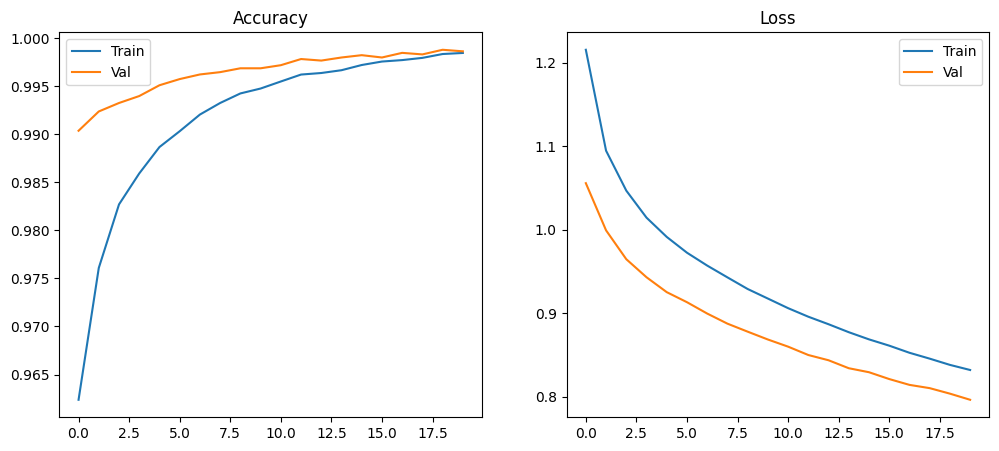

In [11]:
plt.figure(figsize=(12, 5))


plt.subplot(1, 2, 1)
plt.plot(history_phase2.history["accuracy"], label="Train")
plt.plot(history_phase2.history["val_accuracy"], label="Val")
plt.title("Accuracy")
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(history_phase2.history["loss"], label="Train")
plt.plot(history_phase2.history["val_loss"], label="Val")
plt.title("Loss")
plt.legend()

plt.show()

In [12]:
test_loss, test_acc = model.evaluate(test_ds)
print("Test Accuracy:", test_acc)
print("Test Loss:", test_loss)

195/195 ━━━━━━━━━━━━━━━━━━━━ 22s 112ms/step - accuracy: 0.9976 - loss: 0.7990
Test Accuracy: 0.998314619064331
Test Loss: 0.7975426912307739


In [13]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
for images, labels in test_ds.take(1):
    print(labels[:10])

y_true = []
y_pred = []

for images, labels in test_ds:
    
    predictions = model.predict(images, verbose=0) 
    predicted_labels = np.argmax(predictions, axis=1)
    
    # Convert true labels from One-Hot to class indices (this is the key modification).
    true_labels = np.argmax(labels.numpy(), axis=1)
    
    
    y_true.extend(true_labels)
    y_pred.extend(predicted_labels)


target_names_list = [idx_to_label[i] for i in range(len(idx_to_label))]


print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(target_names_list))),
    target_names=target_names_list,
    zero_division=0
))


tf.Tensor(
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.

In [14]:


# Save the final model in Keras H5 format
final_model_path = './plant_disease_classifier_efficientnetb0.keras'
model.save(final_model_path)
print(f"Model saved to {final_model_path}")
import json

metadata = {
    "class_names": target_names_list,
    "img_size": [224, 224],
    "num_classes": len(target_names_list),
    "model_type": "EfficientNetB0",
    "label_smoothing": 0.1
}

with open("model_metadata.json", "w") as f:
    json.dump(metadata, f)



Model saved to ./plant_disease_classifier_efficientnetb0.keras
